## 0. Code (PROMETHEE package) – run, no need to read

In [1]:
import os
os.makedirs('promethee', exist_ok=True)
os.makedirs('data', exist_ok=True)

In [2]:
%%writefile promethee/__init__.py
"""Own-code PROMETHEE I/II with sensitivity analysis, F-PROMETHEE and efficiency extension."""
from .core import (Criterion, Problem, PrometheeResult, kendall_tau, normalise,
                   preference_matrices, promethee, promethee_I, ranks_from_scores,
                   spearman_rho, unicriterion_flows, weighted_sum,
                   normalised_matrix)

__all__ = ["Criterion", "Problem", "PrometheeResult", "kendall_tau", "normalise",
           "preference_matrices", "promethee", "promethee_I", "ranks_from_scores",
           "spearman_rho", "unicriterion_flows", "weighted_sum", "normalised_matrix"]

Writing promethee/__init__.py


In [3]:
%%writefile promethee/core.py
"""Core PROMETHEE I / II implementation (own code, numpy only).

Notation
--------
* ``X``      – performance matrix, shape (n_alternatives, n_criteria)
* ``w``      – criteria weights (normalised to sum 1)
* ``P_j(a,b)`` – unicriterion preference degree of ``a`` over ``b`` on criterion j
* ``pi(a,b) = sum_j w_j P_j(a,b)`` – aggregated preference index
* ``phi+ (a) = 1/(n-1) sum_b pi(a,b)`` – positive (leaving) flow
* ``phi- (a) = 1/(n-1) sum_b pi(b,a)`` – negative (entering) flow
* ``phi  (a) = phi+(a) - phi-(a)``     – net flow (PROMETHEE II)

Because ``phi(a) = sum_j w_j phi_j(a)`` (``phi_j`` = unicriterion net flow), the
net flow is *linear in the weights*; the sensitivity module exploits this.
"""
from __future__ import annotations

import json
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np

# ---------------------------------------------------------------------------
# Preference functions (Brans & Vincke, 6 generalised criteria)
# d = difference g(a) - g(b) already oriented so that "positive = better"
# ---------------------------------------------------------------------------


def _usual(d, q=0.0, p=0.0, s=0.0):
    return (d > 0).astype(float)


def _u_shape(d, q=0.0, p=0.0, s=0.0):
    return (d > q).astype(float)


def _v_shape(d, q=0.0, p=1.0, s=0.0):
    return np.clip(d / p, 0.0, 1.0) * (d > 0)


def _level(d, q=0.0, p=1.0, s=0.0):
    return np.where(d > p, 1.0, np.where(d > q, 0.5, 0.0))


def _linear(d, q=0.0, p=1.0, s=0.0):
    span = p - q if p > q else 1.0          # p == q degenerates to U-shape
    return np.where(d > p, 1.0, np.where(d > q, (d - q) / span, 0.0))


def _gaussian(d, q=0.0, p=0.0, s=1.0):
    return np.where(d > 0, 1.0 - np.exp(-(d**2) / (2 * s**2)), 0.0)


PREFERENCE_FUNCTIONS = {
    "usual": _usual,        # type I
    "u-shape": _u_shape,    # type II   (q)
    "v-shape": _v_shape,    # type III  (p)
    "level": _level,        # type IV   (q, p)
    "linear": _linear,      # type V    (q, p)  "V-shape with indifference"
    "gaussian": _gaussian,  # type VI   (s)
}


@dataclass
class Criterion:
    id: str
    name: str
    direction: str = "max"          # "max" or "min"
    function: str = "usual"
    q: float = 0.0
    p: float = 0.0
    s: float = 0.0

    def preference(self, d: np.ndarray) -> np.ndarray:
        if self.direction == "min":
            d = -d
        fn = PREFERENCE_FUNCTIONS[self.function]
        return fn(d, q=self.q, p=self.p, s=self.s)


@dataclass
class Problem:
    title: str
    alt_ids: list[str]
    alt_names: list[str]
    criteria: list[Criterion]
    X: np.ndarray
    weights: np.ndarray
    weight_scenarios: dict[str, np.ndarray] = field(default_factory=dict)
    config: dict = field(default_factory=dict)

    @property
    def labels(self) -> list[str]:
        return [f"{i} {n}" for i, n in zip(self.alt_ids, self.alt_names)]

    @classmethod
    def from_json(cls, path: str | Path) -> "Problem":
        cfg = json.loads(Path(path).read_text(encoding="utf-8"))
        alt_ids = list(cfg["alternatives"].keys())
        crit = [Criterion(**{k: v for k, v in c.items()}) for c in cfg["criteria"]]
        X = np.array([cfg["performance"][a] for a in alt_ids], dtype=float)
        scen = {k: normalise(v) for k, v in cfg.get("weight_scenarios", {}).items()}
        return cls(
            title=cfg.get("title", "MCDM problem"),
            alt_ids=alt_ids,
            alt_names=[cfg["alternatives"][a] for a in alt_ids],
            criteria=crit,
            X=X,
            weights=normalise(cfg["weights"]),
            weight_scenarios=scen,
            config=cfg,
        )


def normalise(w) -> np.ndarray:
    w = np.asarray(w, dtype=float)
    if np.any(w < 0) or w.sum() <= 0:
        raise ValueError("weights must be non-negative and not all zero")
    return w / w.sum()


# ---------------------------------------------------------------------------
# PROMETHEE computations
# ---------------------------------------------------------------------------


def preference_matrices(X: np.ndarray, criteria: list[Criterion]) -> np.ndarray:
    """Unicriterion preference degrees, shape (m, n, n): P[j, a, b]."""
    n, m = X.shape
    P = np.empty((m, n, n))
    for j, c in enumerate(criteria):
        d = X[:, j][:, None] - X[:, j][None, :]
        P[j] = c.preference(d)
        np.fill_diagonal(P[j], 0.0)
    return P


def unicriterion_flows(P: np.ndarray) -> np.ndarray:
    """phi_j(a), shape (n, m)."""
    m, n, _ = P.shape
    return ((P.sum(axis=2) - P.sum(axis=1)) / (n - 1)).T


@dataclass
class PrometheeResult:
    pi: np.ndarray
    phi_plus: np.ndarray
    phi_minus: np.ndarray
    phi: np.ndarray
    phi_j: np.ndarray

    def ranking(self) -> np.ndarray:
        """Indices of alternatives from best to worst (PROMETHEE II)."""
        return np.argsort(-self.phi, kind="stable")

    def ranks(self) -> np.ndarray:
        """Rank position (1 = best) of each alternative."""
        return ranks_from_scores(self.phi)


def ranks_from_scores(scores: np.ndarray) -> np.ndarray:
    order = np.argsort(-np.asarray(scores), kind="stable")
    r = np.empty(len(order), dtype=int)
    r[order] = np.arange(1, len(order) + 1)
    return r


def promethee(X: np.ndarray, criteria: list[Criterion], w, P: np.ndarray | None = None
              ) -> PrometheeResult:
    w = normalise(w)
    if P is None:
        P = preference_matrices(X, criteria)
    n = X.shape[0]
    pi = np.tensordot(w, P, axes=1)
    phi_plus = pi.sum(axis=1) / (n - 1)
    phi_minus = pi.sum(axis=0) / (n - 1)
    return PrometheeResult(pi, phi_plus, phi_minus, phi_plus - phi_minus,
                           unicriterion_flows(P))


def promethee_I(res: PrometheeResult, tol: float = 1e-9) -> np.ndarray:
    """PROMETHEE I partial preorder.

    Returns matrix R with R[a,b] in {'P', 'I', 'R', '-'}:
    'P' a outranks b, 'I' indifferent, 'R' incomparable, '-' b outranks a.
    """
    n = len(res.phi)
    R = np.full((n, n), "", dtype=object)
    fp, fm = res.phi_plus, res.phi_minus
    for a in range(n):
        for b in range(n):
            if a == b:
                R[a, b] = "="
                continue
            plus_ge, plus_gt = fp[a] >= fp[b] - tol, fp[a] > fp[b] + tol
            min_le, min_lt = fm[a] <= fm[b] + tol, fm[a] < fm[b] - tol
            plus_eq = abs(fp[a] - fp[b]) <= tol
            min_eq = abs(fm[a] - fm[b]) <= tol
            if plus_eq and min_eq:
                R[a, b] = "I"
            elif plus_ge and min_le and (plus_gt or min_lt):
                R[a, b] = "P"
            elif (fp[b] >= fp[a] - tol) and (fm[b] <= fm[a] + tol):
                R[a, b] = "-"
            else:
                R[a, b] = "R"
    return R


# ---------------------------------------------------------------------------
# Reference method for comparison: weighted sum  S = N x W  ("P x W")
# ---------------------------------------------------------------------------


def normalised_matrix(X: np.ndarray, criteria: list[Criterion], method: str = "ratio"
                      ) -> np.ndarray:
    """Normalised performances, higher = better.

    ratio  : x / max (benefit), min / x (cost) – the normalisation used in Task 1
    minmax : (x - min) / (max - min), reversed for cost criteria
    """
    X = np.asarray(X, float)
    N = np.empty_like(X)
    for j, c in enumerate(criteria):
        col = X[:, j]
        if method == "ratio":
            N[:, j] = col.min() / col if c.direction == "min" else col / col.max()
        elif method == "minmax":
            span = col.max() - col.min() or 1.0
            v = (col - col.min()) / span
            N[:, j] = 1.0 - v if c.direction == "min" else v
        else:
            raise ValueError(method)
    return N


def weighted_sum(X: np.ndarray, criteria: list[Criterion], w, method: str = "ratio"
                 ) -> np.ndarray:
    """WSM score S = N x W (simple additive weighting)."""
    return normalised_matrix(X, criteria, method) @ normalise(w)


# ---------------------------------------------------------------------------
# Rank correlation helpers
# ---------------------------------------------------------------------------


def kendall_tau(r1, r2) -> float:
    r1, r2 = np.asarray(r1), np.asarray(r2)
    n = len(r1)
    s = 0
    for i in range(n):
        for j in range(i + 1, n):
            s += np.sign(r1[i] - r1[j]) * np.sign(r2[i] - r2[j])
    return 2 * s / (n * (n - 1))


def spearman_rho(r1, r2) -> float:
    r1, r2 = np.asarray(r1, float), np.asarray(r2, float)
    n = len(r1)
    return 1 - 6 * np.sum((r1 - r2) ** 2) / (n * (n**2 - 1))

Writing promethee/core.py


In [4]:
%%writefile promethee/sensitivity.py
"""Sensitivity analysis for PROMETHEE II (own code).

Contents
--------
* ``stability_intervals`` – exact weight-stability intervals per criterion
  (for the complete ranking and for the first position).
* ``weight_sweep``        – one-at-a-time sweep of a weight from 0 to 1.
* ``monte_carlo``         – random weights (whole simplex or local perturbation),
  rank-acceptability indices.
* ``threshold_sensitivity`` – scaling of the preference thresholds q, p, s and
  replacement of all preference functions by the "usual" criterion.

All weight analyses use the standard convention: when the weight of criterion
j becomes t, the remaining weights keep their mutual proportions and are
rescaled to sum to 1 - t.
"""
from __future__ import annotations

import copy

import numpy as np

from .core import (Criterion, kendall_tau, normalise, preference_matrices, promethee,
                   ranks_from_scores, unicriterion_flows)


def _phi_rest(phi_j: np.ndarray, w: np.ndarray, j: int) -> np.ndarray:
    """Net flow obtained from all criteria except j (weights renormalised)."""
    rest = np.delete(np.arange(len(w)), j)
    wr = w[rest]
    if wr.sum() == 0:
        return np.zeros(phi_j.shape[0])
    return phi_j[:, rest] @ (wr / wr.sum())


def phi_with_weight(phi_j: np.ndarray, w: np.ndarray, j: int, t: float) -> np.ndarray:
    return t * phi_j[:, j] + (1 - t) * _phi_rest(phi_j, w, j)


def stability_intervals(phi_j: np.ndarray, w, tol: float = 1e-12):
    """Exact stability intervals of each weight.

    phi_a(t) - phi_b(t) is linear in t, so each pair (a,b) swaps order at most
    once; the interval around the current weight is bounded by the closest
    swap points.

    Returns list of dicts with keys: criterion index, weight, ranking interval
    (lo, hi), top-1 interval (lo, hi).
    """
    w = normalise(w)
    n, m = phi_j.shape
    out = []
    for j in range(m):
        pj = phi_j[:, j]
        pr = _phi_rest(phi_j, w, j)
        base = phi_with_weight(phi_j, w, j, w[j])
        best = int(np.argmax(base))
        lo_all, hi_all, lo_top, hi_top = 0.0, 1.0, 0.0, 1.0
        for a in range(n):
            for b in range(a + 1, n):
                dr = pr[a] - pr[b]
                dj = pj[a] - pj[b]
                slope = dj - dr
                if abs(slope) < tol:
                    continue
                t = -dr / slope
                if not (0.0 < t < 1.0):
                    continue
                involves_best = best in (a, b)
                if t <= w[j] + tol:
                    lo_all = max(lo_all, t)
                    if involves_best:
                        lo_top = max(lo_top, t)
                if t >= w[j] - tol:
                    hi_all = min(hi_all, t)
                    if involves_best:
                        hi_top = min(hi_top, t)
        out.append({"j": j, "weight": w[j], "rank_lo": lo_all, "rank_hi": hi_all,
                    "top_lo": lo_top, "top_hi": hi_top, "best": best})
    return out


def weight_sweep(phi_j: np.ndarray, w, j: int, steps: int = 101):
    w = normalise(w)
    ts = np.linspace(0, 1, steps)
    flows = np.array([phi_with_weight(phi_j, w, j, t) for t in ts])
    return ts, flows


def monte_carlo(phi_j: np.ndarray, w=None, n_samples: int = 20000, mode: str = "simplex",
                spread: float = 0.2, seed: int = 42):
    """Rank acceptability analysis.

    mode="simplex": weights uniformly distributed on the whole simplex
                    (Dirichlet(1,...,1)) – "what if we know nothing about weights".
    mode="local":   each base weight multiplied by U(1-spread, 1+spread), then
                    renormalised – "what if our weights are imprecise".

    Returns (acceptability[n, n], mean_rank[n], weights_sample).
    acceptability[a, r] = share of samples in which alternative a has rank r+1.
    """
    rng = np.random.default_rng(seed)
    n, m = phi_j.shape
    if mode == "simplex":
        W = rng.dirichlet(np.ones(m), size=n_samples)
    elif mode == "local":
        w = normalise(w)
        W = w * rng.uniform(1 - spread, 1 + spread, size=(n_samples, m))
        W /= W.sum(axis=1, keepdims=True)
    else:
        raise ValueError(mode)
    PHI = W @ phi_j.T                       # (samples, n)
    order = np.argsort(-PHI, axis=1, kind="stable")
    R = np.empty_like(order)
    rows = np.arange(n_samples)[:, None]
    R[rows, order] = np.arange(1, n + 1)
    acc = np.zeros((n, n))
    for r in range(n):
        acc[:, r] = (R == r + 1).mean(axis=0)
    return acc, R.mean(axis=0), W


def threshold_sensitivity(X: np.ndarray, criteria: list[Criterion], w,
                          factors=(0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0)):
    """Scale all thresholds (q, p, s) by a factor and recompute the ranking.

    Also evaluates the variant where every criterion uses the 'usual'
    preference function (no thresholds at all).
    Returns list of (label, phi, ranks, kendall_tau_vs_base).
    """
    base = promethee(X, criteria, w)
    base_r = base.ranks()
    rows = []
    for f in factors:
        crit = copy.deepcopy(criteria)
        for c in crit:
            c.q, c.p, c.s = c.q * f, c.p * f, c.s * f
        res = promethee(X, crit, w)
        rows.append((f"thresholds x{f:g}", res.phi, res.ranks(),
                     kendall_tau(base_r, res.ranks())))
    crit = copy.deepcopy(criteria)
    for c in crit:
        c.function = "usual"
    res = promethee(X, crit, w)
    rows.append(("all 'usual' (type I)", res.phi, res.ranks(),
                 kendall_tau(base_r, res.ranks())))
    return rows


def single_threshold_sweep(X, criteria, w, j: int, param: str, values):
    """Vary a single threshold of criterion j; return net flows per value."""
    flows = []
    for v in values:
        crit = copy.deepcopy(criteria)
        setattr(crit[j], param, v)
        if crit[j].function in ("linear", "level") and crit[j].q > crit[j].p:
            crit[j].q = crit[j].p
        P = preference_matrices(X, crit)
        flows.append(unicriterion_flows(P) @ normalise(w))
    return np.array(flows)


__all__ = ["stability_intervals", "weight_sweep", "monte_carlo",
           "threshold_sensitivity", "single_threshold_sweep", "phi_with_weight",
           "ranks_from_scores"]

Writing promethee/sensitivity.py


In [5]:
%%writefile promethee/efficiency.py
"""Efficiency measuring (own code).

Efficiency (cost vs. benefit)
-----------------------------
The criteria are split into COST criteria (here: price) and BENEFIT criteria
(everything the money buys).  For each alternative two PROMETHEE scores are
computed from the unicriterion net flows phi_j:

    phi_benefit(a) = sum_{j in benefit} w_j phi_j(a) / sum_{j in benefit} w_j
    phi_cost(a)    = sum_{j in cost}    w_j phi_j(a) / sum_{j in cost}    w_j

(higher = better for both; for the price, higher phi = cheaper).
An alternative is EFFICIENT if no other alternative is at least as good on
both scores and strictly better on one (Pareto / non-dominated).  Moving along
the efficient frontier shows how much extra money buys how much extra benefit.

Best choice for a budget
------------------------
Reading the frontier for a budget B: among the printers with price <= B,
take the one with the highest benefit flow.  (This is NOT PROMETHEE V:
PROMETHEE V selects a portfolio, i.e. a combination of several alternatives;
here exactly one printer is bought.)
"""
from __future__ import annotations

from itertools import combinations

import numpy as np

from .core import normalise


def split_flows(phi_j: np.ndarray, w, cost_idx: list[int]):
    """Return (phi_benefit, phi_cost) for every alternative."""
    w = normalise(w)
    m = phi_j.shape[1]
    cost = np.zeros(m, bool)
    cost[list(cost_idx)] = True
    wb, wc = np.where(cost, 0, w), np.where(cost, w, 0)
    return phi_j @ (wb / wb.sum()), phi_j @ (wc / wc.sum())


def efficient_set(benefit: np.ndarray, cost_score: np.ndarray) -> np.ndarray:
    """Boolean mask of non-dominated alternatives (both scores: higher = better)."""
    n = len(benefit)
    eff = np.ones(n, bool)
    for a in range(n):
        for b in range(n):
            if b != a and benefit[b] >= benefit[a] and cost_score[b] >= cost_score[a] \
                    and (benefit[b] > benefit[a] or cost_score[b] > cost_score[a]):
                eff[a] = False
                break
    return eff


def best_within_budget(scores: np.ndarray, costs: np.ndarray, budget: float,
                       min_items: int = 1, max_items: int = 1):
    """Best affordable choice by enumeration. Returns (best subset tuple, total score)."""
    n = len(scores)
    best, best_val = (), -np.inf
    for k in range(min_items, max_items + 1):
        for sub in combinations(range(n), k):
            if costs[list(sub)].sum() <= budget + 1e-9:
                val = scores[list(sub)].sum()
                if val > best_val + 1e-12:
                    best, best_val = sub, val
    return best, best_val


def budget_sweep(scores: np.ndarray, costs: np.ndarray, budgets):
    """Best affordable printer for every budget; -1 = nothing affordable."""
    out = []
    for b in budgets:
        sub, _ = best_within_budget(scores, costs, b)
        out.append(sub[0] if sub else -1)
    return np.array(out)


def efficiency_acceptability(phi_j: np.ndarray, w, cost_idx, n_samples: int = 20000,
                             mode: str = "local", spread: float = 0.2, seed: int = 11):
    """Share of random weight vectors for which each alternative is efficient."""
    rng = np.random.default_rng(seed)
    m = phi_j.shape[1]
    if mode == "local":
        W = normalise(w) * rng.uniform(1 - spread, 1 + spread, size=(n_samples, m))
    else:
        W = rng.dirichlet(np.ones(m), size=n_samples)
    counts = np.zeros(phi_j.shape[0])
    for wk in W:
        b, c = split_flows(phi_j, wk, cost_idx)
        counts += efficient_set(b, c)
    return counts / n_samples

Writing promethee/efficiency.py


In [6]:
%%writefile promethee/fuzzy.py
"""F-PROMETHEE with triangular fuzzy numbers (own code).

Every uncertain value is a triangular fuzzy number (TFN) (l, m, u):
m = the value used in the crisp analysis, l / u = lowest / highest plausible.
Crisp values are TFNs with l = m = u.

All PROMETHEE steps are done on the three numbers (l, m, u) with standard
TFN arithmetic (cf. Goumas & Lygerou, 2000):

1. fuzzy difference      d~ = a~ - b~ = (a_l - b_u,  a_m - b_m,  a_u - b_l)
2. fuzzy preference      P~ = (P(d_l), P(d_m), P(d_u))   (sorted, so l <= m <= u)
3. fuzzy index           pi~(a,b) = sum_j w~_j P~_j(a,b),  w~_j = (w_j (1-s), w_j, w_j (1+s))
                         (TFN product of positive numbers: (w_l P_l, w_m P_m, w_u P_u))
4. fuzzy flows           phi+~ = mean_b pi~(a,b),   phi-~ = mean_b pi~(b,a)
5. fuzzy net flow        phi~ = phi+~ - phi-~ = (phi+_l - phi-_u, phi+_m - phi-_m, phi+_u - phi-_l)
6. ranking               centroid (l + m + u) / 3

The middle value m is exactly the crisp PROMETHEE II net flow.
"""
from __future__ import annotations

import numpy as np

from .core import Criterion, normalise


def fuzzy_matrix(X: np.ndarray, criteria: list[Criterion], alt_ids: list[str], spec: list[dict]):
    """Build the TFN matrix (L, M, U) from the JSON spec; unlisted criteria stay crisp."""
    X = np.asarray(X, float)
    L, M, U = X.copy(), X.copy(), X.copy()
    ids = [c.id for c in criteria]
    for s in spec:
        j = ids.index(s["criterion"])
        if "relative" in s:
            L[:, j], U[:, j] = X[:, j] * (1 - s["relative"]), X[:, j] * (1 + s["relative"])
        if "absolute" in s:
            L[:, j], U[:, j] = X[:, j] - s["absolute"], X[:, j] + s["absolute"]
        if "clip" in s:
            L[:, j], U[:, j] = np.clip(L[:, j], *s["clip"]), np.clip(U[:, j], *s["clip"])
        for alt, (lo, mid, hi) in s.get("override", {}).items():
            i = alt_ids.index(alt)
            L[i, j], M[i, j], U[i, j] = lo, mid, hi
    return L, M, U


def fuzzy_promethee(L, M, U, criteria: list[Criterion], w, w_spread: float = 0.0):
    """F-PROMETHEE II. Weights are TFNs (w(1-s), w, w(1+s)) with s = w_spread.
    Returns dict with TFN arrays of shape (n, 3) = (l, m, u):
    'pi' (n, n, 3), 'phi_plus', 'phi_minus', 'phi', and 'centroid' (n,)."""
    w = normalise(w)
    wt = np.stack([w * (1 - w_spread), w, w * (1 + w_spread)], axis=1)  # (m, 3)
    n, m = L.shape
    pi = np.zeros((n, n, 3))
    for j, c in enumerate(criteria):
        for a in range(n):
            for b in range(n):
                if a == b:
                    continue
                d = np.array([L[a, j] - U[b, j], M[a, j] - M[b, j], U[a, j] - L[b, j]])
                pi[a, b] += wt[j] * np.sort(c.preference(d))
    phi_plus = pi.sum(axis=1) / (n - 1)
    phi_minus = pi.sum(axis=0) / (n - 1)
    phi = np.stack([phi_plus[:, 0] - phi_minus[:, 2],
                    phi_plus[:, 1] - phi_minus[:, 1],
                    phi_plus[:, 2] - phi_minus[:, 0]], axis=1)
    return {"pi": pi, "phi_plus": phi_plus, "phi_minus": phi_minus, "phi": phi,
            "centroid": phi.mean(axis=1)}

Writing promethee/fuzzy.py


In [7]:
%%writefile run_analysis.py
"""Run the complete Task 2 analysis: PROMETHEE I/II, ranking comparison,
sensitivity analysis, F-PROMETHEE, what-if analysis and the efficiency extension.

Usage:  python run_analysis.py [path/to/problem.json]

Outputs: results/*.csv, results/figures/*.png, results/results.md
"""
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from matplotlib.colors import LinearSegmentedColormap  # noqa: E402

from promethee import (Problem, kendall_tau, promethee, promethee_I,  # noqa: E402
                       ranks_from_scores, spearman_rho, weighted_sum)
from promethee.efficiency import (best_within_budget, budget_sweep,  # noqa: E402
                                  efficiency_acceptability, efficient_set, split_flows)
from promethee.fuzzy import fuzzy_matrix, fuzzy_promethee  # noqa: E402
from promethee.sensitivity import (monte_carlo, single_threshold_sweep,  # noqa: E402
                                   stability_intervals, threshold_sensitivity,
                                   weight_sweep)

ROOT = Path(__file__).parent
OUT = ROOT / "results"
FIG = OUT / "figures"

# --- chart styling (validated categorical palette, recessive axes) ----------
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
          "#6250d6", "#e34948"]
INK, INK2, GRID, AXIS = "#1f1f1e", "#5f5e58", "#e1e0d9", "#c3c2b7"
BLUE, RED, MID = "#2a78d6", "#e34948", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("div", [RED, MID, BLUE])
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "seq", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 9.5, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2,
})


def md_table(df: pd.DataFrame, floatfmt: str = "{:.4f}") -> str:
    cols = [str(df.index.name or "")] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in zip(df.index, df.astype(object).itertuples(index=False)):
        cells = [str(idx)]
        for col, v in zip(df.columns, row):
            if pd.api.types.is_integer_dtype(df[col].dtype):
                cells.append(str(int(v)))
            elif isinstance(v, (float, np.floating)):
                cells.append("–" if np.isnan(v) else floatfmt.format(v))
            else:
                cells.append(str(v))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


def spread_labels(y, min_gap):
    """Return label positions with at least ``min_gap`` between neighbours."""
    y = np.asarray(y, float)
    order = np.argsort(y)
    pos = y[order].copy()
    for k in range(1, len(pos)):
        pos[k] = max(pos[k], pos[k - 1] + min_gap)
    shift = (pos - y[order]).mean()
    pos -= shift / 2
    out = np.empty_like(pos)
    out[order] = pos
    return out


def save(fig, name):
    fig.savefig(FIG / name, facecolor="white")
    plt.close(fig)


def main(path: str):
    OUT.mkdir(exist_ok=True)
    FIG.mkdir(exist_ok=True)
    pb = Problem.from_json(path)
    n, m = pb.X.shape
    A, C = pb.alt_ids, [c.id for c in pb.criteria]
    cnames = [c.name for c in pb.criteria]
    color = {a: SERIES[i % len(SERIES)] for i, a in enumerate(A)}
    md: list[str] = [f"# Results (auto-generated) – {pb.title}\n",
                     "_Generated by `run_analysis.py`. Interpretation: see `REPORT.md`._\n"]

    # ------------------------------------------------------------------ data
    perf = pd.DataFrame(pb.X, index=pb.labels, columns=cnames)
    perf.index.name = "Alternative"
    params = pd.DataFrame([{"criterion": c.name, "direction": c.direction,
                            "function": c.function, "q": c.q, "p": c.p, "s": c.s,
                            "weight": w} for c, w in zip(pb.criteria, pb.weights)],
                          index=C)
    params.index.name = "id"
    perf.to_csv(OUT / "performance_table.csv")
    params.to_csv(OUT / "criteria_parameters.csv")
    md += ["## 1. Input data\n", md_table(perf, "{:g}"), "",
           md_table(params, "{:g}"), ""]

    # readable overview of every input per criterion (for presenting the model)
    def _unit(name):
        return name[name.find("[") + 1:name.find("]")] if "[" in name else ""

    def _meaning(c, u):
        u = f" {u}" if u and not u.startswith("1-") else ""
        if c.function == "usual":
            return "any difference = clearly better"
        if c.function == "u-shape":
            return f"≤ {c.q:g}{u}: no difference; more = clearly better"
        if c.function == "v-shape":
            return f"each unit counts; ≥ {c.p:g}{u} = clearly better"
        if c.function == "level":
            return (f"≤ {c.q:g}{u}: no difference; up to {c.p:g}{u}: half; "
                    f"> {c.p:g}{u}: clearly better")
        if c.function == "linear":
            return (f"≤ {c.q:g}{u}: no difference; grows linearly; "
                    f"≥ {c.p:g}{u}: clearly better")
        return f"gaussian, s = {c.s:g}"

    fz_spec = {s_["criterion"]: s_ for s_ in pb.config.get("fuzzy", {}).get("values", [])}
    eff_cost = set(pb.config.get("efficiency", {}).get("cost_criteria", []))
    w_m2 = pb.weight_scenarios.get("M2 rank sum")

    def _tfn(c):
        s_ = fz_spec.get(c.id)
        if not s_:
            return "exact"
        u = _unit(c.name)
        u = f" {u}" if u and not u.startswith("1-") else ""
        txt = f"±{s_['relative']:.0%}" if "relative" in s_ else f"±{s_['absolute']:g}{u}"
        for alt, v in s_.get("override", {}).items():
            txt += f"; {pb.alt_names[A.index(alt)]}: ({v[0]:g}; {v[1]:g}; {v[2]:g})"
        return txt

    overview = pd.DataFrame({
        "criterion": [c.name.split(" [")[0] for c in pb.criteria],
        "unit": [_unit(c.name) for c in pb.criteria],
        "better": ["lower" if c.direction == "min" else "higher" for c in pb.criteria],
        "weight M1 (base)": pb.weights,
        "weight M2": w_m2 if w_m2 is not None else np.nan,
        "preference function": [c.function for c in pb.criteria],
        "q": [f"{c.q:g}" if c.function in ("u-shape", "level", "linear") else "–"
              for c in pb.criteria],
        "p": [f"{c.p:g}" if c.function in ("v-shape", "level", "linear") else "–"
              for c in pb.criteria],
        "what the thresholds mean": [_meaning(c, _unit(c.name)) for c in pb.criteria],
        "uncertainty (TFN)": [_tfn(c) for c in pb.criteria],
        "efficiency role": ["input (cost)" if c.id in eff_cost else "output (benefit)"
                            for c in pb.criteria],
    }, index=C)
    overview.index.name = "id"
    overview.to_csv(OUT / "inputs_overview.csv")
    md += ["### Inputs overview\n", md_table(overview, "{:g}"), ""]

    # ------------------------------------------------------- PROMETHEE I/II
    res = promethee(pb.X, pb.criteria, pb.weights)
    flows = pd.DataFrame({"phi+": res.phi_plus, "phi-": res.phi_minus,
                          "phi (net)": res.phi, "rank": res.ranks()}, index=pb.labels)
    flows.index.name = "Alternative"
    flows = flows.sort_values("rank")
    flows.to_csv(OUT / "promethee_flows.csv")
    pi_df = pd.DataFrame(res.pi, index=A, columns=A)
    pi_df.index.name = "pi(a,b)"
    pi_df.to_csv(OUT / "preference_index_matrix.csv")
    uni = pd.DataFrame(res.phi_j, index=pb.labels, columns=cnames)
    uni.index.name = "Alternative"
    uni.to_csv(OUT / "unicriterion_net_flows.csv")

    R1 = promethee_I(res)
    p1 = pd.DataFrame(R1, index=A, columns=A)
    p1.index.name = "a \\ b"
    p1.to_csv(OUT / "promethee_I_relations.csv")
    pairs_P, pairs_R = [], []
    for a in range(n):
        for b in range(n):
            if R1[a, b] == "P":
                pairs_P.append(f"{A[a]} P {A[b]}")
            if R1[a, b] == "R" and a < b:
                pairs_R.append(f"{A[a]} R {A[b]}")

    md += ["## 2. PROMETHEE II – complete ranking\n", md_table(flows), "",
           "### Aggregated preference indices pi(a,b)\n", md_table(pi_df, "{:.3f}"), "",
           "### Unicriterion net flows phi_j(a)\n", md_table(uni, "{:+.3f}"), "",
           "## 3. PROMETHEE I – partial preorder\n",
           "P = row outranks column, - = column outranks row, R = incomparable, "
           "I = indifferent\n", md_table(p1), "",
           f"Incomparable pairs: {', '.join(pairs_R) if pairs_R else 'none'}\n"]

    # fig: net flows
    order = res.ranking()
    fig, ax = plt.subplots(figsize=(7, 3.4))
    labels = [pb.labels[i] for i in order][::-1]
    vals = res.phi[order][::-1]
    ax.barh(labels, vals, color=[BLUE if v >= 0 else RED for v in vals], height=0.6)
    for y, v in enumerate(vals):
        ax.text(v + (0.006 if v >= 0 else -0.006), y, f"{v:+.3f}", va="center",
                ha="left" if v >= 0 else "right", color=INK, fontsize=9)
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_xlabel("net flow φ")
    lim = np.abs(vals).max() * 1.3
    ax.set_xlim(-lim, lim)
    ax.grid(axis="y", visible=False)
    ax.set_title("PROMETHEE II complete ranking (base weights)", loc="left")
    save(fig, "01_net_flows.png")

    # fig: PROMETHEE I – phi+ / phi- scales
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    ax.grid(False)
    yl = res.phi_plus
    yr = 1 - res.phi_minus
    gap = 0.045 * (max(yl.max(), yr.max()) - min(yl.min(), yr.min()))
    ly, ry = spread_labels(yl, gap), spread_labels(yr, gap)
    for i, a in enumerate(A):
        ax.plot([0, 1], [yl[i], yr[i]], color=color[a], marker="o", ms=7,
                mec="white", mew=1.5)
        ax.text(-0.04, ly[i], f"{pb.labels[i]}  {res.phi_plus[i]:.3f}",
                ha="right", va="center", fontsize=8.5, color=INK)
        ax.text(1.04, ry[i], f"{res.phi_minus[i]:.3f}  {pb.labels[i]}",
                ha="left", va="center", fontsize=8.5, color=INK)
    ax.set_xlim(-0.9, 1.9)
    ax.set_xticks([0, 1], ["φ+ (higher = better)", "φ− (lower = better, axis inverted)"])
    ax.set_yticks([])
    for s in ("left", "bottom"):
        ax.spines[s].set_visible(False)
    ax.set_title("PROMETHEE I: crossing lines = incomparability", loc="left")
    save(fig, "02_promethee_I.png")

    # fig: unicriterion flow profile heatmap
    fig, ax = plt.subplots(figsize=(7.2, 3.4))
    ax.grid(False)
    im = ax.imshow(res.phi_j, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
    xt = [c.id + "\n" + c.name.replace(" [", "\n[") for c in pb.criteria]
    ax.set_xticks(range(m), xt, fontsize=8)
    ax.set_yticks(range(n), pb.labels)
    for i in range(n):
        for j in range(m):
            ax.text(j, i, f"{res.phi_j[i, j]:+.2f}", ha="center", va="center",
                    color=INK if abs(res.phi_j[i, j]) < 0.6 else "white", fontsize=8.5)
    fig.colorbar(im, ax=ax, fraction=0.03, label="φj")
    ax.set_title("Unicriterion net flows – strengths (blue) and weaknesses (red)",
                 loc="left")
    save(fig, "03_unicriterion_profiles.png")

    # ----------------------------------------- ranking comparison / scenarios
    md.append("## 4. Comparison of rankings\n")
    scen = dict(pb.weight_scenarios) or {"Base": pb.weights}
    wsm_norm = pb.config.get("weighted_sum_normalisation", "ratio")
    rows_phi, rows_rank = {}, {}
    for name, w in scen.items():
        rr = promethee(pb.X, pb.criteria, w)
        rows_phi[f"PROMETHEE II – {name}"] = rr.phi
        rows_rank[f"PROMETHEE II – {name}"] = rr.ranks()
    for name, w in scen.items():
        ws = weighted_sum(pb.X, pb.criteria, w, wsm_norm)
        rows_phi[f"Weighted sum (P×W) – {name}"] = ws
        rows_rank[f"Weighted sum (P×W) – {name}"] = ranks_from_scores(ws)
    rank_df = pd.DataFrame(rows_rank, index=A).T
    rank_df.index.name = "Method / weights"
    score_df = pd.DataFrame(rows_phi, index=A).T
    score_df.index.name = "Method / weights"
    rank_df.to_csv(OUT / "ranking_comparison_ranks.csv")
    score_df.to_csv(OUT / "ranking_comparison_scores.csv")
    wtab = pd.DataFrame(scen, index=C).T
    wtab.index.name = "Scenario"
    base_key = next(iter(rows_rank))
    corr = pd.DataFrame({
        "Kendall τ vs base": [kendall_tau(rows_rank[base_key], r) for r in rows_rank.values()],
        "Spearman ρ vs base": [spearman_rho(rows_rank[base_key], r) for r in rows_rank.values()],
        "Best": [A[int(np.argmin(r))] for r in rows_rank.values()],
    }, index=rows_rank.keys())
    corr.index.name = "Method / weights"
    md += ["### Weight scenarios\n", md_table(wtab, "{:.3f}"), "",
           "### Ranks (1 = best)\n", md_table(rank_df, "{:d}"), "",
           f"### Scores (net flow φ for PROMETHEE, WSM score with `{wsm_norm}` "
           "normalisation for P×W)\n",
           md_table(score_df, "{:+.3f}"), "",
           f"### Rank correlation with `{base_key}`\n", md_table(corr, "{:.3f}"), ""]
    # PROMETHEE vs P×W within each scenario
    pw = pd.DataFrame({
        "Kendall τ (PROMETHEE vs P×W)": [
            kendall_tau(rows_rank[f"PROMETHEE II – {k}"], rows_rank[f"Weighted sum (P×W) – {k}"])
            for k in scen]}, index=list(scen))
    pw.index.name = "Scenario"
    md += [md_table(pw, "{:.3f}"), ""]

    # fig: rank comparison heatmap (ranks)
    fig, ax = plt.subplots(figsize=(7.6, 0.42 * len(rank_df) + 1.2))
    ax.grid(False)
    rv = rank_df.values.astype(float)
    ax.imshow(-rv, cmap=SEQUENTIAL, aspect="auto", vmin=-n - 1.5, vmax=0)
    for i in range(rv.shape[0]):
        for j in range(n):
            ax.text(j, i, int(rv[i, j]), ha="center", va="center",
                    color="white" if rv[i, j] <= 2 else INK, fontsize=9,
                    fontweight="bold" if rv[i, j] == 1 else "normal")
    ax.set_xticks(range(n), pb.labels, rotation=25, ha="right")
    ax.set_yticks(range(len(rank_df)), rank_df.index, fontsize=8.5)
    ax.axhline(len(scen) - 0.5, color="white", lw=4)
    ax.set_title("Rank of each alternative under each method and weight scenario "
                 "(1 = best)", loc="left")
    save(fig, "04_ranking_comparison.png")

    # ------------------------------------------------- sensitivity: weights
    md.append("## 5. Sensitivity analysis\n")
    stab = stability_intervals(res.phi_j, pb.weights)
    st_df = pd.DataFrame([{
        "criterion": cnames[s["j"]], "weight": s["weight"],
        "ranking stable from": s["rank_lo"], "ranking stable to": s["rank_hi"],
        "best stays best from": s["top_lo"], "best stays best to": s["top_hi"],
    } for s in stab], index=C)
    st_df.index.name = "id"
    st_df.to_csv(OUT / "weight_stability_intervals.csv")
    md += ["### 5.1 Weight stability intervals (exact)\n",
           "Other weights keep their proportions. `best` = "
           f"{pb.labels[stab[0]['best']]}.\n", md_table(st_df, "{:.3f}"), ""]

    # fig: OAT sweeps, small multiples
    cols = 3
    rows = int(np.ceil(m / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(11, 3.1 * rows), sharey=True)
    axes = np.atleast_1d(axes).ravel()
    for j in range(m):
        ax = axes[j]
        ts, fl = weight_sweep(res.phi_j, pb.weights, j)
        s = stab[j]
        ax.axvspan(s["rank_lo"], s["rank_hi"], color="#cde2fb", alpha=0.7, lw=0)
        for i, a in enumerate(A):
            ax.plot(ts, fl[:, i], color=color[a], label=pb.labels[i])
        ax.axvline(pb.weights[j], color=INK2, lw=1, ls="--")
        ax.set_title(f"{pb.criteria[j].id} {cnames[j]}", loc="left", fontsize=9.5)
        ax.set_xlabel(f"weight of {pb.criteria[j].id}")
        ax.axhline(0, color=AXIS, lw=0.8)
    for k in range(m, len(axes)):
        axes[k].axis("off")
    axes[0].set_ylabel("net flow φ")
    handles, lbls = axes[0].get_legend_handles_labels()
    if m % cols:
        fig.legend(handles, lbls, loc="lower right", bbox_to_anchor=(0.97, 0.12),
                   ncol=1, fontsize=8.5)
    else:
        fig.legend(handles, lbls, loc="upper center", bbox_to_anchor=(0.5, 0.0),
                   ncol=n, fontsize=8.5)
    fig.suptitle("Net flow vs weight of one criterion (dashed = base weight, "
                 "shaded = ranking unchanged)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save(fig, "05_weight_sweeps.png")

    # Monte Carlo
    acc_s, mr_s, _ = monte_carlo(res.phi_j, mode="simplex")
    acc_l, mr_l, _ = monte_carlo(res.phi_j, pb.weights, mode="local", spread=0.2)
    acc_l30, mr_l30, _ = monte_carlo(res.phi_j, pb.weights, mode="local", spread=0.5)
    rcols = [f"rank {r + 1}" for r in range(n)]
    acc_sdf = pd.DataFrame(acc_s, index=pb.labels, columns=rcols)
    acc_sdf["mean rank"] = mr_s
    acc_ldf = pd.DataFrame(acc_l, index=pb.labels, columns=rcols)
    acc_ldf["mean rank"] = mr_l
    acc_l5 = pd.DataFrame(acc_l30, index=pb.labels, columns=rcols)
    acc_l5["mean rank"] = mr_l30
    for d in (acc_sdf, acc_ldf, acc_l5):
        d.index.name = "Alternative"
    acc_sdf.to_csv(OUT / "rank_acceptability_simplex.csv")
    acc_ldf.to_csv(OUT / "rank_acceptability_local20.csv")
    acc_l5.to_csv(OUT / "rank_acceptability_local50.csv")
    md += ["### 5.2 Monte-Carlo rank acceptability (20 000 weight vectors)\n",
           "**(a) local: every base weight perturbed by ±20 %**\n",
           md_table(acc_ldf, "{:.3f}"), "",
           "**(b) local: every base weight perturbed by ±50 %**\n",
           md_table(acc_l5, "{:.3f}"), "",
           "**(c) global: weights uniformly random on the whole simplex**\n",
           md_table(acc_sdf, "{:.3f}"), ""]

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
    for ax, acc, ttl in zip(axes, (acc_l, acc_l30, acc_s),
                            ("±20 % around base weights", "±50 % around base weights",
                             "any weights (uniform simplex)")):
        ax.grid(False)
        ax.imshow(acc, cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
        for i in range(n):
            for r in range(n):
                if acc[i, r] >= 0.005:
                    ax.text(r, i, f"{acc[i, r]:.0%}", ha="center", va="center",
                            fontsize=8, color="white" if acc[i, r] > 0.5 else INK)
        ax.set_xticks(range(n), [str(r + 1) for r in range(n)])
        ax.set_xlabel("rank position")
        ax.set_title(ttl, loc="left", fontsize=10)
    axes[0].set_yticks(range(n), pb.labels)
    fig.suptitle("Rank acceptability: share of random weight vectors giving each rank",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save(fig, "06_rank_acceptability.png")

    # ------------------------------------------- sensitivity: thresholds
    th = threshold_sensitivity(pb.X, pb.criteria, pb.weights)
    th_df = pd.DataFrame([{**{A[i]: int(r[i]) for i in range(n)},
                           "Kendall τ vs base": tau, "best": A[int(np.argmax(phi))]}
                          for _, phi, r, tau in th], index=[t[0] for t in th])
    th_df.index.name = "Preference-function variant"
    th_df.to_csv(OUT / "threshold_sensitivity.csv")
    md += ["### 5.3 Preference-function / threshold sensitivity (ranks)\n",
           md_table(th_df, "{:.3f}"), ""]

    # single-threshold sweeps for criteria having p
    sweep_c = [j for j, c in enumerate(pb.criteria) if c.function in
               ("linear", "v-shape", "level")]
    if sweep_c:
        ncol = min(3, len(sweep_c))
        nrow = int(np.ceil(len(sweep_c) / ncol))
        fig, axes = plt.subplots(nrow, ncol, figsize=(3.9 * ncol + 1.6, 3.0 * nrow),
                                 sharey=True, squeeze=False)
        axes = axes.ravel()
        for k in range(len(sweep_c), len(axes)):
            axes[k].axis("off")
        for ax, j in zip(axes, sweep_c):
            c = pb.criteria[j]
            vals = np.linspace(max(c.q, 1e-6) if c.function != "v-shape" else 1e-6,
                               3 * c.p, 60)
            fl = single_threshold_sweep(pb.X, pb.criteria, pb.weights, j, "p", vals)
            for i, a in enumerate(A):
                ax.plot(vals, fl[:, i], color=color[a], label=pb.labels[i])
            ax.axvline(c.p, color=INK2, lw=1, ls="--")
            ax.set_title(f"{c.id}: preference threshold p", loc="left", fontsize=9.5)
            ax.set_xlabel(f"p ({c.name})")
        for k in range(0, len(axes), ncol):
            axes[k].set_ylabel("net flow φ")
        axes[ncol - 1].legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.02, 1.0))
        fig.suptitle("Net flows vs preference threshold p (dashed = value used)",
                     x=0.01, ha="left", fontweight="bold")
        fig.tight_layout()
        save(fig, "07_threshold_sweeps.png")

    # ------------------------------------------------ F-PROMETHEE (fuzzy)
    fz = pb.config.get("fuzzy")
    if fz:
        L, M, U = fuzzy_matrix(pb.X, pb.criteria, A, fz["values"])

        def _f(v):
            return f"{v:.0f}" if abs(v) >= 100 else f"{v:g}"
        tfn = pd.DataFrame({cnames[j]: [f"({_f(L[i, j])}; {_f(M[i, j])}; {_f(U[i, j])})"
                                        if L[i, j] != U[i, j] else f"{_f(M[i, j])}"
                                        for i in range(n)] for j in range(m)},
                           index=pb.labels)
        tfn.index.name = "Alternative"
        tfn.to_csv(OUT / "fuzzy_decision_matrix.csv")
        ws = float(fz.get("weight_spread", 0.0))
        fr = fuzzy_promethee(L, M, U, pb.criteria, pb.weights, ws)
        ph = fr["phi"]
        fp = pd.DataFrame({"φ l": ph[:, 0], "φ m (= crisp φ)": ph[:, 1], "φ u": ph[:, 2],
                           "centroid (l+m+u)/3": fr["centroid"],
                           "F-PROMETHEE rank": ranks_from_scores(fr["centroid"])},
                          index=pb.labels)
        fp.index.name = "Alternative"
        fp = fp.sort_values("F-PROMETHEE rank")
        fp.to_csv(OUT / "fuzzy_promethee.csv")
        md += ["### 5.4 F-PROMETHEE – uncertain values as triangular fuzzy numbers\n",
               "Fuzzy decision matrix (l; m; u):\n", md_table(tfn), "",
               f"Weights are TFNs too: ({1 - ws:g}·w; w; {1 + ws:g}·w).\n",
               "Fuzzy net flows φ~ = (l; m; u) and ranking by the centroid:\n",
               md_table(fp, "{:+.3f}"), ""]

        fig, ax = plt.subplots(figsize=(7.8, 3.6))
        for i, a in enumerate(A):
            xs, ys = [ph[i, 0], ph[i, 1], ph[i, 2]], [0, 1, 0]
            ax.fill(xs, ys, color=color[a], alpha=0.15, lw=0)
            ax.plot(xs, ys, color=color[a], label=pb.labels[i])
            ax.plot([fr["centroid"][i]] * 2, [0, 0.06], color=color[a], lw=2.5)
        ax.axvline(0, color=AXIS, lw=0.8)
        ax.set_xlabel("fuzzy net flow φ~  (short tick = centroid)")
        ax.set_ylabel("membership")
        ax.set_ylim(0, 1.08)
        ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
        ax.set_title("F-PROMETHEE: fuzzy net flow of each printer (l; m; u)", loc="left")
        save(fig, "11_f_promethee.png")

    # --------------------------------------------- what-if: one performance
    wi = pb.config.get("what_if")
    if wi:
        ai, cj = A.index(wi["alternative"]), C.index(wi["criterion"])
        vals = np.linspace(wi["values_from"], wi["values_to"], 361)
        fl = []
        for v in vals:
            Xv = pb.X.copy()
            Xv[ai, cj] = v
            fl.append(promethee(Xv, pb.criteria, pb.weights).phi)
        fl = np.array(fl)
        win = fl.argmax(axis=1)
        # value where the alternative starts / stops being the winner
        is_best = win == ai
        switch = []
        for k in range(1, len(vals)):
            if is_best[k] != is_best[k - 1]:
                # interpolate where the alternative ties with the other leader
                other = win[k] if win[k] != ai else win[k - 1]
                d0 = fl[k - 1, ai] - fl[k - 1, other]
                d1 = fl[k, ai] - fl[k, other]
                switch.append(vals[k - 1] + (vals[k] - vals[k - 1]) * d0 / (d0 - d1))
        cur = pb.X[ai, cj]
        tab = []
        for v in sorted(set([cur, *[round(x) for x in np.linspace(wi["values_from"],
                                                                  wi["values_to"], 7)]])):
            Xv = pb.X.copy()
            Xv[ai, cj] = v
            rr = promethee(Xv, pb.criteria, pb.weights)
            tab.append({"value": v, **{A[i]: rr.phi[i] for i in range(n)},
                        "winner": pb.labels[int(np.argmax(rr.phi))],
                        f"rank of {A[ai]}": int(rr.ranks()[ai])})
        wi_df = pd.DataFrame(tab).set_index("value")
        wi_df.to_csv(OUT / "what_if.csv")
        md += [f"### 5.5 What-if: {wi.get('description', '')}\n",
               f"Varying `{cnames[cj]}` of {pb.labels[ai]} (current value {cur:g}), "
               "base weights.\n", md_table(wi_df, "{:+.3f}"), "",
               "Winner changes at: " + (", ".join(f"{x:.0f}" for x in switch)
                                        if switch else "never in this range") + "\n"]
        fig, ax = plt.subplots(figsize=(7.6, 3.6))
        for i, a in enumerate(A):
            ax.plot(vals, fl[:, i], color=color[a], label=pb.labels[i],
                    lw=2.6 if i == ai else 2)
        ax.axvline(cur, color=INK2, lw=1, ls="--")
        ax.text(cur, ax.get_ylim()[1], f" current {cur:g}", color=INK2, fontsize=8,
                va="top")
        for x in switch:
            ax.axvline(x, color=INK, lw=1, ls=":")
            ax.text(x, ax.get_ylim()[0], f" {x:.0f}", color=INK, fontsize=8,
                    va="bottom")
        ax.set_xlabel(f"{cnames[cj]} of {pb.labels[ai]}")
        ax.set_ylabel("net flow φ")
        ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
        ax.set_title(wi.get("description", "What-if"), loc="left")
        save(fig, "08_what_if.png")

    # ------------------------------------------ extension: efficiency measuring
    eff_cfg = pb.config.get("efficiency")
    if eff_cfg:
        cidx = [C.index(c) for c in eff_cfg["cost_criteria"]]
        bidx = [j for j in range(m) if j not in cidx]
        price = pb.X[:, cidx[0]]
        ben, cst = split_flows(res.phi_j, pb.weights, cidx)
        eff = efficient_set(ben, cst)
        # who dominates the inefficient ones
        dom_by = []
        for a in range(n):
            ds = [A[b] for b in range(n) if b != a and ben[b] >= ben[a] and cst[b] >= cst[a]
                  and (ben[b] > ben[a] or cst[b] > cst[a])]
            dom_by.append(", ".join(ds) if ds else "–")
        eff_df = pd.DataFrame({
            cnames[cidx[0]]: price.round().astype(int), "φ benefit (5 criteria)": ben,
            "φ cost (price)": cst, "efficient": np.where(eff, "yes", "no"),
            "dominated by": dom_by}, index=pb.labels)
        eff_df.index.name = "Alternative"
        eff_df = eff_df.sort_values(cnames[cidx[0]])
        eff_df.to_csv(OUT / "efficiency.csv")
        # steps along the frontier: extra money per extra benefit
        fr = sorted(np.where(eff)[0], key=lambda i: price[i])
        steps = []
        for i, k in zip(fr[:-1], fr[1:]):
            dp, db = price[k] - price[i], ben[k] - ben[i]
            steps.append({"from": pb.labels[i], "to": pb.labels[k], "extra price [EUR]": int(round(dp)),
                          "extra φ benefit": db, "EUR per +0.1 φ benefit": int(round(dp / db * 0.1))})
        step_df = pd.DataFrame(steps)
        if len(step_df):
            step_df = step_df.set_index("from")
        # reading the frontier: best printer (max benefit flow) for every budget
        budgets = np.arange(eff_cfg["budget_from"], eff_cfg["budget_to"] + 1, 1.0)
        choice = budget_sweep(ben, price, budgets)
        rows, prev = [], None
        for bgt, ch in zip(budgets, choice):
            if ch != prev:
                rows.append({"budget from [EUR]": bgt,
                             "best choice": pb.labels[ch] if ch >= 0 else "nothing affordable",
                             "φ benefit": ben[ch] if ch >= 0 else np.nan})
                prev = ch
        pv_df = pd.DataFrame(rows)
        pv_df["budget from [EUR]"] = pv_df["budget from [EUR]"].astype(int)
        pv_df = pv_df.set_index("budget from [EUR]")
        pv_df.to_csv(OUT / "budget_choice.csv")
        pv_task1, _ = best_within_budget(ben, price, 2500)
        pv_full, _ = best_within_budget(res.phi, price, 2500)
        # robustness: how often is each printer efficient under random weights
        acc = {f"efficient (±{int(s * 100)}%)": efficiency_acceptability(res.phi_j, pb.weights,
                                                                        cidx, spread=s)
               for s in (0.2, 0.5)}
        acc["efficient (any w)"] = efficiency_acceptability(res.phi_j, pb.weights, cidx,
                                                            mode="simplex")
        acc_df = pd.DataFrame(acc, index=pb.labels)
        acc_df.index.name = "Alternative"
        acc_df.to_csv(OUT / "efficiency_acceptability.csv")
        md += ["## 6. Extension – efficiency measuring\n",
               eff_cfg.get("description", ""), "",
               "### Cost and benefit flows, efficient set\n", md_table(eff_df, "{:+.3f}"), "",
               "### Steps along the efficient frontier\n",
               md_table(step_df, "{:+.3f}") if len(step_df) else "only one efficient printer", "",
               "### Reading the frontier: best printer (max φ benefit) for each budget\n",
               md_table(pv_df, "{:+.3f}"), "",
               f"With the Task 1 budget of 2500 EUR: maximising the benefit flow selects "
               f"**{pb.labels[pv_task1[0]]}**; maximising the full net flow (price as a "
               f"criterion) selects **{pb.labels[pv_full[0]]}**.\n",
               "### Robustness: share of random weight vectors for which a printer is "
               "efficient\n", md_table(acc_df, "{:.3f}"), ""]

        # fig: efficient frontier
        fig, ax = plt.subplots(figsize=(7.8, 4.4))
        order_fr = np.array(fr)
        ax.step(np.r_[price[order_fr], price.max() * 1.08], np.r_[ben[order_fr], ben[order_fr][-1]],
                where="post", color=AXIS, lw=1.5, zorder=1)
        for i, a in enumerate(A):
            ax.scatter(price[i], ben[i], s=130 if eff[i] else 90, color=color[a],
                       edgecolor=INK if eff[i] else "white", lw=2 if eff[i] else 1.5,
                       zorder=5, marker="o" if eff[i] else "X")
            tag = "efficient" if eff[i] else f"dominated by {dom_by[i]}"
            right = price[i] > np.median(price)
            ax.annotate(f"{pb.labels[i]}\n{tag}", (price[i], ben[i]),
                        textcoords="offset points", xytext=(-12 if right else 10, -6),
                        ha="right" if right else "left", va="top", fontsize=8.5, color=INK)
        ax.axhline(0, color=AXIS, lw=0.8)
        ax.set_xlabel(f"{cnames[cidx[0]]} (cost)")
        ax.set_ylabel("φ benefit (other criteria)")
        ax.set_xlim(price.min() * 0.85, price.max() * 1.15)
        pad = 0.25 * (ben.max() - ben.min())
        ax.set_ylim(ben.min() - pad, ben.max() + pad * 0.5)
        ax.set_title("Efficient frontier: input = price, output = φ benefit "
                     "(up-left is better)", loc="left")
        save(fig, "09_efficiency_frontier.png")

        # fig: best choice for each budget
        fig, ax = plt.subplots(figsize=(7.8, 1.9))
        ax.grid(axis="y", visible=False)
        ax.set_ylim(-0.45, 0.45)
        seg_start = 0
        for k in range(1, len(budgets) + 1):
            if k == len(budgets) or choice[k] != choice[seg_start]:
                ch = choice[seg_start]
                if ch >= 0:
                    ax.barh(0, budgets[k - 1] - budgets[seg_start] + 1, left=budgets[seg_start],
                            color=color[A[ch]], height=0.5, edgecolor="white", lw=2)
                    ax.text((budgets[seg_start] + budgets[k - 1]) / 2, 0, pb.alt_names[ch],
                            ha="center", va="center", fontsize=8.5,
                            color="white" if A[ch] != "A4" else INK)
                else:
                    ax.text((budgets[seg_start] + budgets[k - 1]) / 2, 0, "none",
                            ha="center", va="center", fontsize=8, color=INK2)
                seg_start = k
        ax.set_yticks([])
        ax.set_xlabel("budget [EUR]")
        ax.set_xlim(budgets[0], budgets[-1])
        ax.set_title("Best printer (max φ benefit) I can buy for a given budget",
                     loc="left")
        save(fig, "10_budget_choice.png")

    (OUT / "results.md").write_text("\n".join(md), encoding="utf-8")
    print("\n".join(md))


if __name__ == "__main__":
    main(sys.argv[1] if len(sys.argv) > 1 else str(ROOT / "data" / "problem.json"))

Writing run_analysis.py


## 1. Problem data

All inputs are in this one file (the code contains no numbers from Task 1):

| part of the file | what it is |
|---|---|
| `alternatives` | the 4 printers A1–A4 |
| `criteria` | the 6 criteria: `direction` (min = lower is better, max = higher is better), `function` (preference function) and its thresholds `q`, `p` |
| `performance` | the decision matrix from Task 1 (one row per printer, columns = criteria C1–C6) |
| `weights` | my weights from Task 1, method 1 (points) |
| `weight_scenarios` | other weight sets for the comparison with the WSM (incl. method 2 and the Task 1 "what if" cases) |
| `fuzzy` | which values are uncertain (triangular fuzzy numbers) and the fuzzy weights (±10 %) |
| `efficiency` | which criterion is the input (price); all others are outputs |

In [8]:
%%writefile data/problem.json
{
  "title": "Which 3D printer should I buy? (FDM printer for home, budget max 2500 EUR)",
  "source": "Task 1 spreadsheet KK_MCDM_1.xlsx",
  "alternatives": {
    "A1": "Creality K2 Plus Combo",
    "A2": "Snapmaker U1",
    "A3": "Bambu Lab H2D",
    "A4": "Prusa CORE One"
  },
  "criteria": [
    {"id": "C1", "name": "Price [EUR]",         "direction": "min", "function": "linear",  "q": 50,  "p": 300},
    {"id": "C2", "name": "Noise [dB(A)]",       "direction": "min", "function": "linear",  "q": 2,   "p": 7},
    {"id": "C3", "name": "Max speed [mm/s]",    "direction": "max", "function": "linear",  "q": 50,  "p": 400},
    {"id": "C4", "name": "Build volume [dm3]",  "direction": "max", "function": "linear",  "q": 2,   "p": 20},
    {"id": "C5", "name": "Ease of use [1-5]",   "direction": "max", "function": "level",   "q": 0.5, "p": 1.5},
    {"id": "C6", "name": "Nozzles [pcs]",       "direction": "max", "function": "v-shape",           "p": 3}
  ],
  "performance": {
    "A1": [1187, 50,   600,  42.875, 3, 1],
    "A2": [899,  55,   500,  19.683, 4, 4],
    "A3": [2125, 49.1, 1000, 33.8,   5, 2],
    "A4": [1282, 48,   600,  14.85,  4, 1]
  },
  "weights": [0.30, 0.15, 0.10, 0.12, 0.08, 0.25],
  "weight_scenarios": {
    "M1 points (base)":         [0.30, 0.15, 0.10, 0.12, 0.08, 0.25],
    "M2 rank sum":              [0.285714, 0.190476, 0.095238, 0.142857, 0.047619, 0.238095],
    "Equal (1/6 each)":         [1, 1, 1, 1, 1, 1],
    "0.2 / 0.15 balanced":      [0.20, 0.15, 0.15, 0.15, 0.15, 0.20],
    "Price matters less":       [0.10, 0.19, 0.13, 0.15, 0.10, 0.33],
    "No multi-colour needed":   [0.40, 0.20, 0.133333, 0.16, 0.106667, 0.0],
    "Big prints":               [0.25, 0.12, 0.08, 0.35, 0.08, 0.12]
  },
  "weighted_sum_normalisation": "ratio",
  "what_if": {
    "description": "What if the Bambu Lab H2D goes on sale? (Task 1, section 6)",
    "alternative": "A3",
    "criterion": "C1",
    "values_from": 700,
    "values_to": 2500
  },
  "fuzzy": {
    "description": "F-PROMETHEE: uncertain values of the decision matrix are triangular fuzzy numbers (low, value used, high); the weights are fuzzy too (±10 %).",
    "weight_spread": 0.1,
    "values": [
      {"criterion": "C1", "relative": 0.05, "override": {"A2": [899, 899, 1099]},
       "why": "prices change from shop to shop (±5 %); the U1 price of 899 EUR is a sale price, normally 1099 EUR"},
      {"criterion": "C2", "absolute": 2, "override": {"A1": [45, 50, 52]},
       "why": "noise values come from different sources (±2 dB); for the K2 Plus the manufacturer states 45 dB, the shop 50 dB"},
      {"criterion": "C5", "absolute": 0.5, "clip": [1, 5],
       "why": "ease of use is my own subjective score (±0.5 point)"}
    ]
  },
  "efficiency": {
    "description": "Efficiency measuring: which printers give the most for the money? Price is the input (cost) criterion, the other five criteria are the outputs (benefit).",
    "cost_criteria": ["C1"],
    "budget_from": 800,
    "budget_to": 2500
  }
}

Writing data/problem.json


## 2. Run the analysis

In [9]:
!python run_analysis.py > /dev/null && echo 'done – results in results/'

done – results in results/


In [10]:
#@title Display settings
import pandas as pd
from IPython.display import Markdown, Image, display
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', '{:g}'.format)

def table(path):
    df = pd.read_csv(path, index_col=0).round(3)
    num = df.select_dtypes('number').columns
    df[num] = df[num] + 0.0  # shows -0.000 as 0
    display(df)

## 3. PROMETHEE I and II

In [11]:
#@title Performance table (from Task 1)
display(Markdown("### Performance table (from Task 1)"))
table("results/performance_table.csv")

### Performance table (from Task 1)

,Price [EUR],Noise [dB(A)],Max speed [mm/s],Build volume [dm3],Ease of use [1-5],Nozzles [pcs]
Alternative,,,,,,
A1 Creality K2 Plus Combo,1187,50,600,42.875,3,1
A2 Snapmaker U1,899,55,500,19.683,4,4
A3 Bambu Lab H2D,2125,49.1,1000,33.8,5,2
A4 Prusa CORE One,1282,48,600,14.85,4,1


In [12]:
#@title Inputs overview – what each input is and what it means
display(Markdown("### Inputs overview – what each input is and what it means"))
table("results/inputs_overview.csv")

### Inputs overview – what each input is and what it means

,criterion,unit,better,weight M1 (base),weight M2,preference function,q,p,what the thresholds mean,uncertainty (TFN),efficiency role
id,,,,,,,,,,,
C1,Price,EUR,lower,0.3,0.286,linear,50,300,≤ 50 EUR: no difference; grows linearly; ≥ 300 EUR: clearly better,±5%; Snapmaker U1: (899; 899; 1099),input (cost)
C2,Noise,dB(A),lower,0.15,0.19,linear,2,7,≤ 2 dB(A): no difference; grows linearly; ≥ 7 dB(A): clearly better,±2 dB(A); Creality K2 Plus Combo: (45; 50; 52),output (benefit)
C3,Max speed,mm/s,higher,0.1,0.095,linear,50,400,≤ 50 mm/s: no difference; grows linearly; ≥ 400 mm/s: clearly better,exact,output (benefit)
C4,Build volume,dm3,higher,0.12,0.143,linear,2,20,≤ 2 dm3: no difference; grows linearly; ≥ 20 dm3: clearly better,exact,output (benefit)
C5,Ease of use,1-5,higher,0.08,0.048,level,0.5,1.5,≤ 0.5: no difference; up to 1.5: half; > 1.5: clearly better,±0.5,output (benefit)
C6,Nozzles,pcs,higher,0.25,0.238,v-shape,–,3,each unit counts; ≥ 3 pcs = clearly better,exact,output (benefit)


**Interpretation.** One row per criterion. The decision matrix and the weights are the same as in Task 1. New for
PROMETHEE is the **preference function**: it says how big a difference has to be before it
matters to me. **q** = the difference I ignore, **p** = the difference from which one printer is
clearly better (column "what the thresholds mean"). For noise q = 2 dB because my noise values come
from different sources, and p = 7 dB, which you clearly hear. Price is very important to me, so
already 300 € is decisive. Ease of use is my own 1–5 score, so I used the level function.
The last two columns are the inputs for the F-PROMETHEE (which values are uncertain) and for the
efficiency analysis (price = input, everything else = output).

### PROMETHEE II – flows and complete ranking

,phi+,phi-,phi (net),rank
Alternative,,,,
A2 Snapmaker U1,0.537,0.242,0.295,1
A1 Creality K2 Plus Combo,0.248,0.293,-0.044,2
A3 Bambu Lab H2D,0.312,0.371,-0.059,3
A4 Prusa CORE One,0.168,0.36,-0.192,4


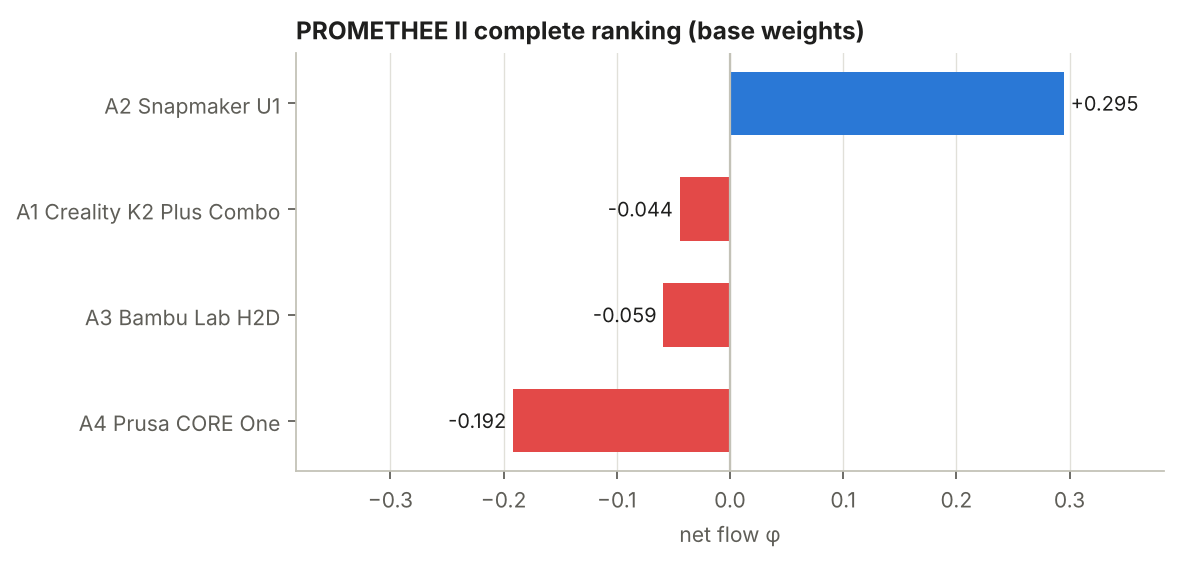

In [13]:
#@title PROMETHEE II – flows and complete ranking
display(Markdown("### PROMETHEE II – flows and complete ranking"))
table("results/promethee_flows.csv")
display(Image("results/figures/01_net_flows.png", width=900))

**Interpretation.** φ⁺ shows how much a printer is better than the others and φ⁻ how much the others are better than
it. The net flow φ = φ⁺ − φ⁻ gives the ranking: **Snapmaker U1 > Creality K2 Plus > Bambu H2D >
Prusa CORE One**. U1 is the only printer with a positive net flow (+0.295) and it is far ahead.
K2 Plus and H2D are almost tied (−0.044 vs −0.059), so I would not read too much into which of
them is 2nd.

### PROMETHEE I – partial ranking

P = row outranks column, `-` = column outranks row, R = incomparable

,A1,A2,A3,A4
a \ b,,,,
A1,=,-,R,P
A2,P,=,P,P
A3,R,-,=,R
A4,-,-,R,=


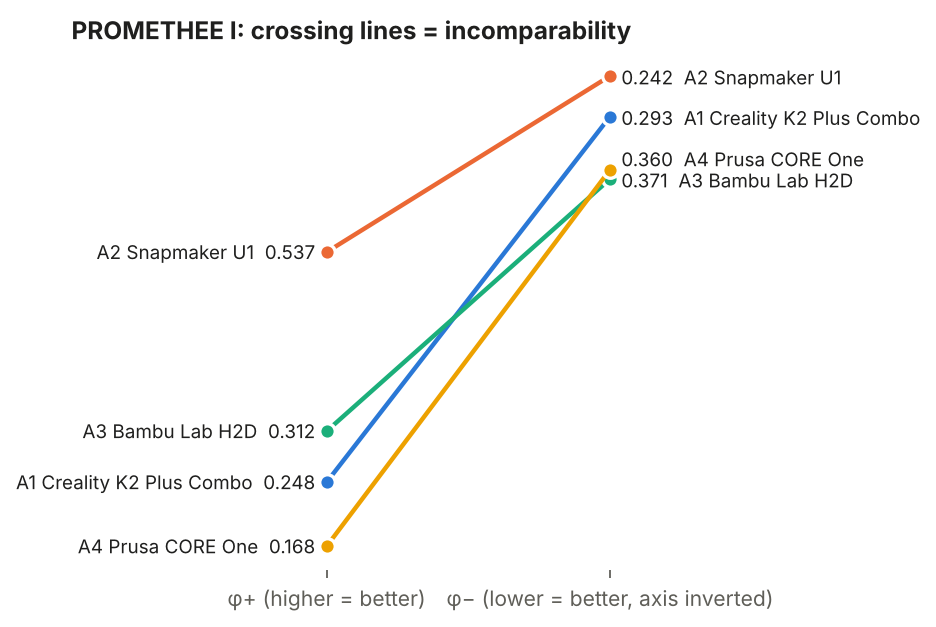

In [14]:
#@title PROMETHEE I – partial ranking
display(Markdown("### PROMETHEE I – partial ranking"))
display(Markdown('P = row outranks column, `-` = column outranks row, R = incomparable'))
table("results/promethee_I_relations.csv")
display(Image("results/figures/02_promethee_I.png", width=900))

**Interpretation.** In PROMETHEE I a printer is better only if it has a higher φ⁺ **and** a lower φ⁻ at the same time.
U1 is better than all three others in this sense, so PROMETHEE I agrees with PROMETHEE II about the
winner. H2D is incomparable (R) with K2 Plus and with the Prusa: it is very good in speed, ease of
use and noise, but much more expensive, so φ⁺ and φ⁻ say different things (the lines cross).

### Strengths and weaknesses (unicriterion net flows)

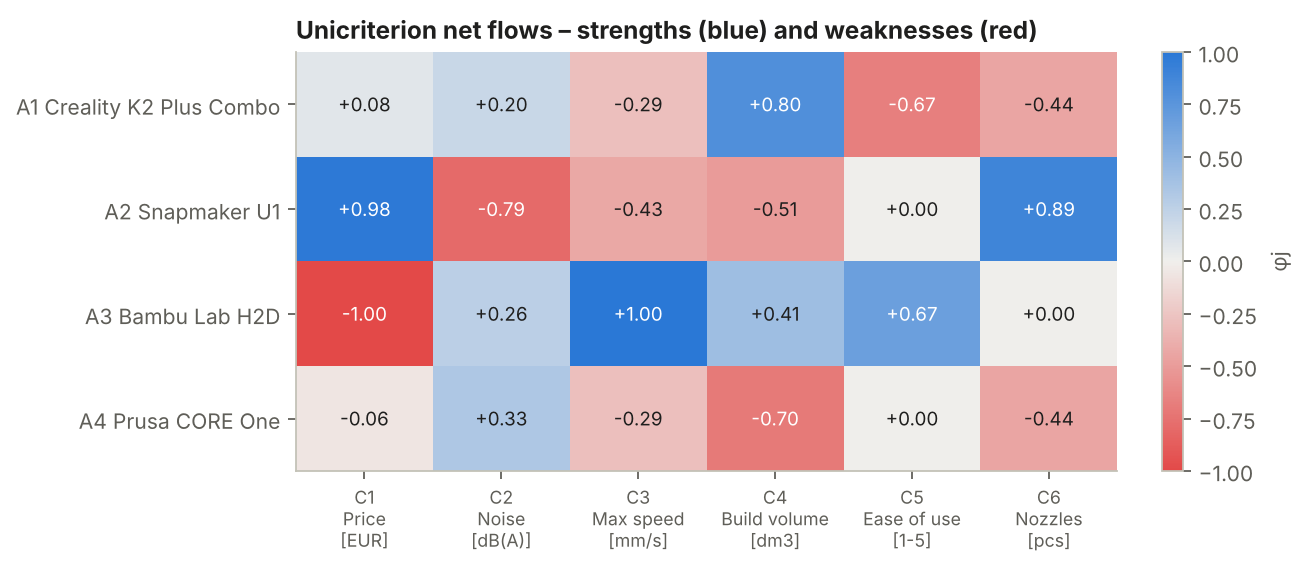

In [15]:
#@title Strengths and weaknesses (unicriterion net flows)
display(Markdown("### Strengths and weaknesses (unicriterion net flows)"))
display(Image("results/figures/03_unicriterion_profiles.png", width=900))

**Interpretation.** This shows why U1 wins: it is the best on price and on nozzles, which are my two most important
criteria (together 55 % of the weight). It is the loudest and slowest printer and has a small
build volume, but these criteria have lower weights. H2D is best on speed and ease of use but has
the worst price.

## 4. Comparison with the WSM from Task 1

### Ranks of PROMETHEE II and WSM for different weights (1 = best)

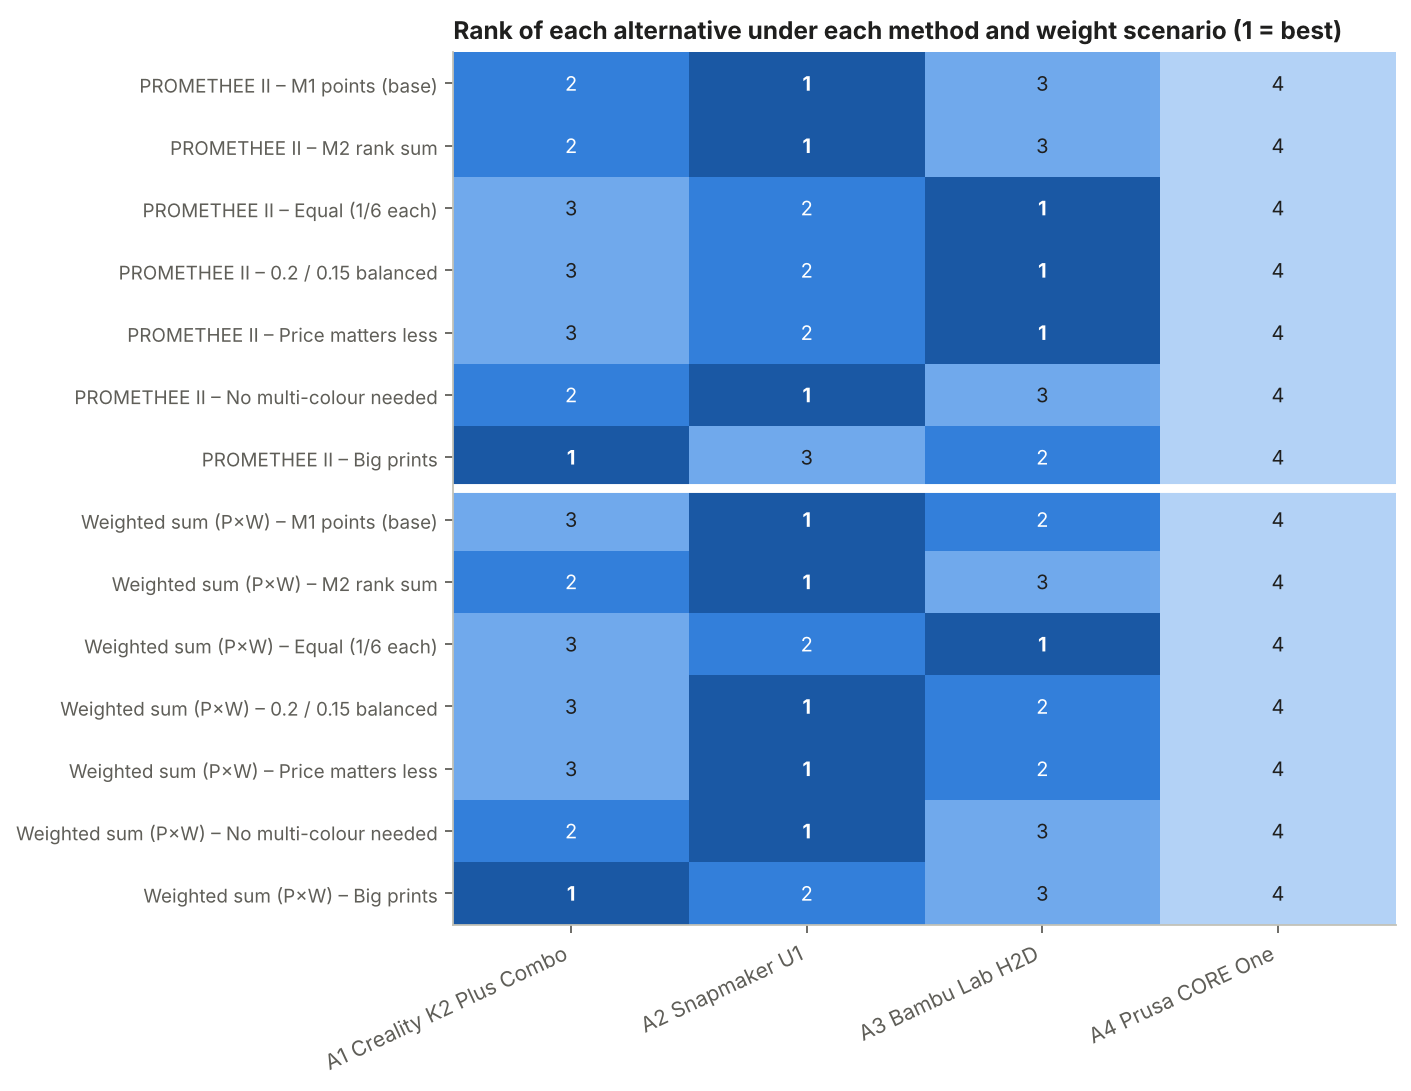

In [16]:
#@title Ranks of PROMETHEE II and WSM for different weights (1 = best)
display(Markdown("### Ranks of PROMETHEE II and WSM for different weights (1 = best)"))
display(Image("results/figures/04_ranking_comparison.png", width=900))

**Interpretation.** With my real weights (method 1 and method 2) both PROMETHEE and the WSM choose **U1**, so the
result of Task 1 is confirmed. The methods differ in the details: with method 1 the WSM has H2D in
2nd place, PROMETHEE has K2 Plus. When price matters less ("Price matters less", "0.2 / 0.15") the
WSM still chooses U1, but PROMETHEE chooses H2D. As I understand it, this is because the WSM counts
every difference proportionally, while PROMETHEE compares pairs and ignores small differences
(below q) and caps big ones (above p). For example U1's advantage of having 4 nozzles counts a lot
in the WSM normalisation, but in PROMETHEE it is limited by the preference function.

## 5. Sensitivity analysis

### Weight stability intervals

,criterion,weight,ranking stable from,ranking stable to,best stays best from,best stays best to
id,,,,,,
C1,Price [EUR],0.3,0.291,0.387,0.148,1
C2,Noise [dB(A)],0.15,0,0.314,0,0.364
C3,Max speed [mm/s],0.1,0,0.11,0,0.279
C4,Build volume [dm3],0.12,0.087,0.302,0,0.302
C5,Ease of use [1-5],0.08,0,0.09,0,0.399
C6,Nozzles [pcs],0.25,0,0.273,0,1


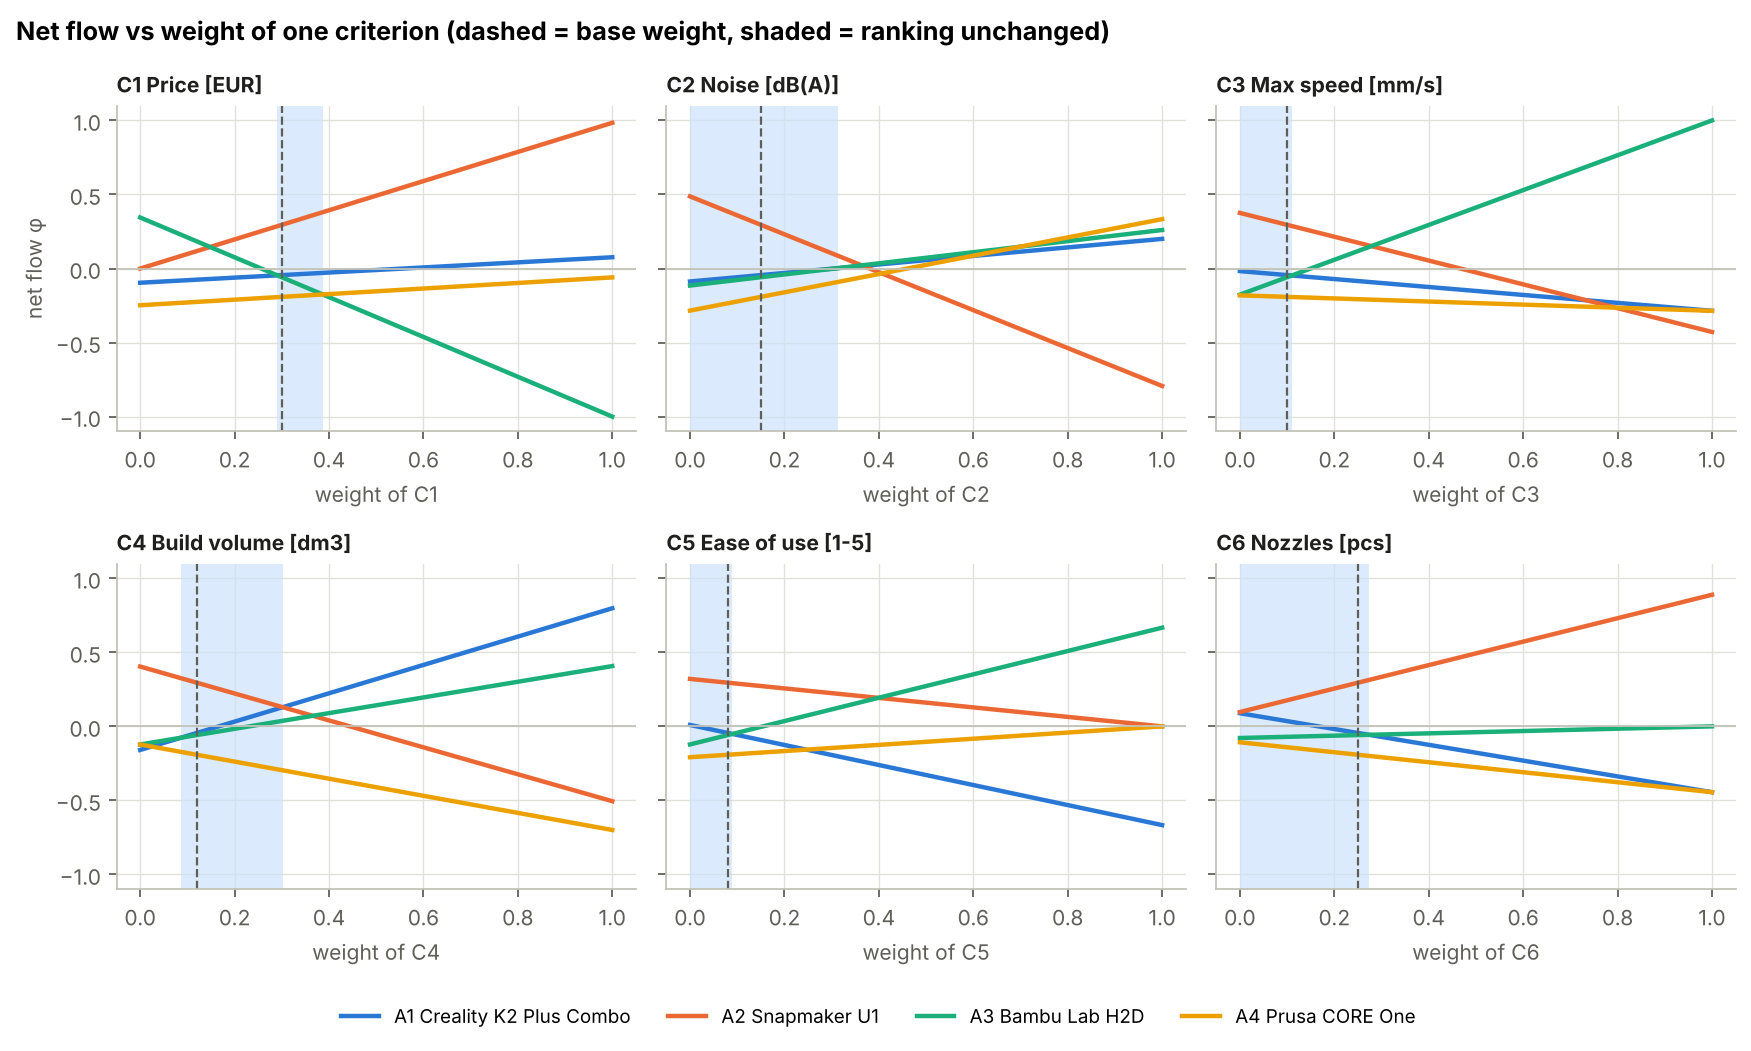

In [17]:
#@title Weight stability intervals
display(Markdown("### Weight stability intervals"))
table("results/weight_stability_intervals.csv")
display(Image("results/figures/05_weight_sweeps.png", width=900))

**Interpretation.** Here I change the weight of one criterion and keep the others in proportion. U1 stays the winner
for every price weight above 0.148 (mine is 0.30) and for any nozzle weight. The other criteria
would need about 2.4 times or more of their weight to change the winner. So the winner is stable;
only the order of places 2 and 3 changes easily.

### Random weights (Monte Carlo)

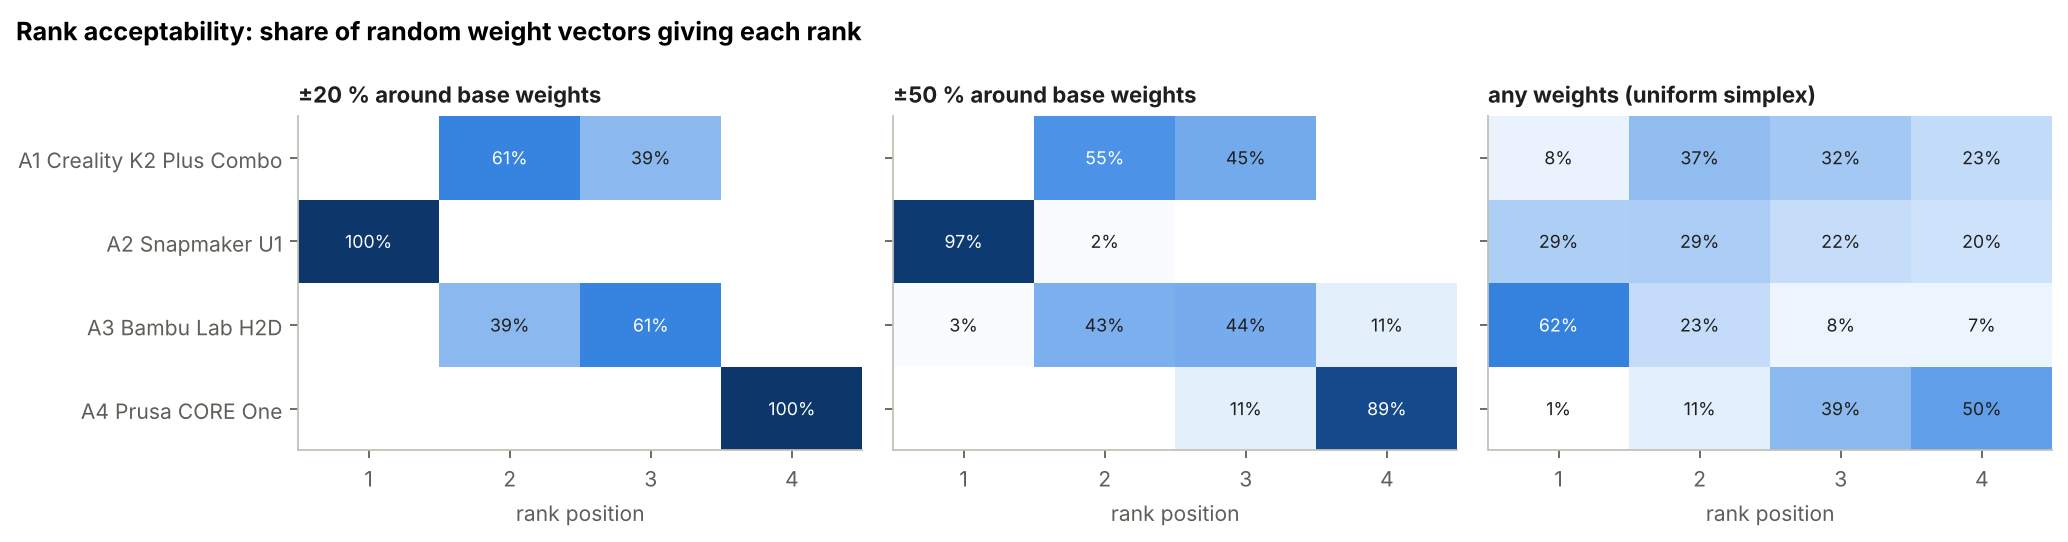

In [18]:
#@title Random weights (Monte Carlo)
display(Markdown("### Random weights (Monte Carlo)"))
display(Image("results/figures/06_rank_acceptability.png", width=900))

**Interpretation.** With weights randomly changed by ±20 % around mine, U1 is first in 100 % of cases, and with ±50 %
in 97 %. With completely random weights H2D wins most often (62 %). So H2D is probably the
"objectively" strongest printer, and U1 wins because of my priorities (low price, multi-colour).

In [19]:
#@title Changing the thresholds q and p
display(Markdown("### Changing the thresholds q and p"))
table("results/threshold_sensitivity.csv")

### Changing the thresholds q and p

,A1,A2,A3,A4,Kendall τ vs base,best
Preference-function variant,,,,,,
thresholds x0.25,3,1,2,4,0.667,A2
thresholds x0.5,3,1,2,4,0.667,A2
thresholds x0.75,2,1,3,4,1,A2
thresholds x1,2,1,3,4,1,A2
thresholds x1.25,2,1,3,4,1,A2
thresholds x1.5,2,1,4,3,0.667,A2
thresholds x2,2,1,4,3,0.667,A2
all 'usual' (type I),3,1,2,4,0.667,A2


**Interpretation.** The thresholds are my own choice, so I multiplied all of them by 0.25 to 2. U1 is first in every
case, only places 2–4 change. So my choice of q and p does not decide the winner.

## 6. Extension (4c) – Efficiency measuring

### Efficient frontier – input: price, output: benefit

,Price [EUR],φ benefit (5 criteria),φ cost (price),efficient,dominated by
Alternative,,,,,
A2 Snapmaker U1,899,0,0.984,yes,–
A1 Creality K2 Plus Combo,1187,-0.096,0.076,no,A2
A4 Prusa CORE One,1282,-0.248,-0.06,no,"A1, A2"
A3 Bambu Lab H2D,2125,0.345,-1,yes,–


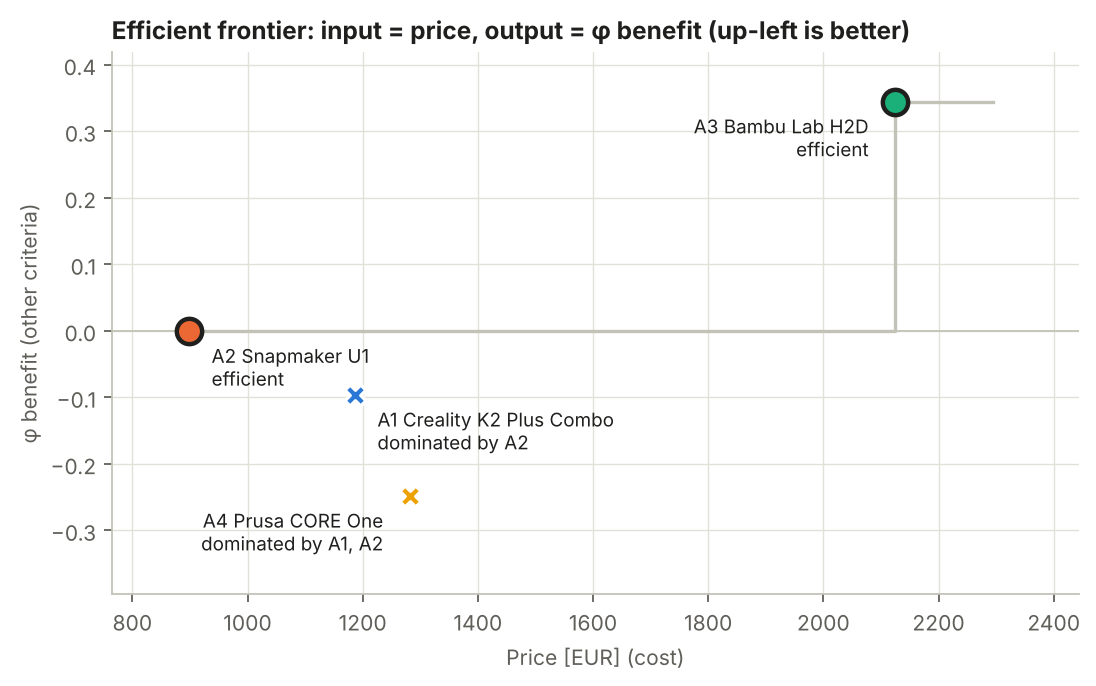

In [20]:
#@title Efficient frontier – input: price, output: benefit
display(Markdown("### Efficient frontier – input: price, output: benefit"))
table("results/efficiency.csv")
display(Image("results/figures/09_efficiency_frontier.png", width=900))

**Interpretation.** My goal in Task 1 was "the printer that gives me the most for my money", so I chose efficiency
measuring. The input is the price and the outputs are the other five criteria (their PROMETHEE
flow = "benefit"). A printer is efficient if no other printer is cheaper and better at the same
time. Only **U1** (cheapest) and **H2D** (best benefit) are efficient. **K2 Plus and Prusa are
dominated by U1**: U1 is cheaper and gives more. So the real choice is only between U1 and paying
1226 € more for H2D. Because price is an important criterion for me, I stay with U1.

## 7. Uncertainty (5a) – F-PROMETHEE

In [21]:
#@title Fuzzy decision matrix (triangular fuzzy numbers l; m; u)
display(Markdown("### Fuzzy decision matrix (triangular fuzzy numbers l; m; u)"))
table("results/fuzzy_decision_matrix.csv")

### Fuzzy decision matrix (triangular fuzzy numbers l; m; u)

,Price [EUR],Noise [dB(A)],Max speed [mm/s],Build volume [dm3],Ease of use [1-5],Nozzles [pcs]
Alternative,,,,,,
A1 Creality K2 Plus Combo,(1128; 1187; 1246),(45; 50; 52),600,42.875,(2.5; 3; 3.5),1
A2 Snapmaker U1,(899; 899; 1099),(53; 55; 57),500,19.683,(3.5; 4; 4.5),4
A3 Bambu Lab H2D,(2019; 2125; 2231),(47.1; 49.1; 51.1),1000,33.8,(4.5; 5; 5),2
A4 Prusa CORE One,(1218; 1282; 1346),(46; 48; 50),600,14.85,(3.5; 4; 4.5),1


**Interpretation.** I replaced the values I am not sure about with triangular fuzzy numbers (lowest; used value;
highest): price ±5 % (different shops) and U1 (899; 899; 1099) because 899 € is a sale price;
noise ±2 dB (different sources) and K2 Plus (45; 50; 52) because the manufacturer says 45 dB;
ease of use ±0.5 because it is my own opinion. The weights are fuzzy too, ±10 %.
Speed, volume and nozzles stay exact (manufacturer data).

### Fuzzy net flows and F-PROMETHEE ranking

,φ l,φ m (= crisp φ),φ u,centroid (l+m+u)/3,F-PROMETHEE rank
Alternative,,,,,
A2 Snapmaker U1,0.005,0.295,0.518,0.273,1
A1 Creality K2 Plus Combo,-0.252,-0.044,0.286,-0.004,2
A3 Bambu Lab H2D,-0.277,-0.059,0.063,-0.091,3
A4 Prusa CORE One,-0.404,-0.192,0.062,-0.178,4


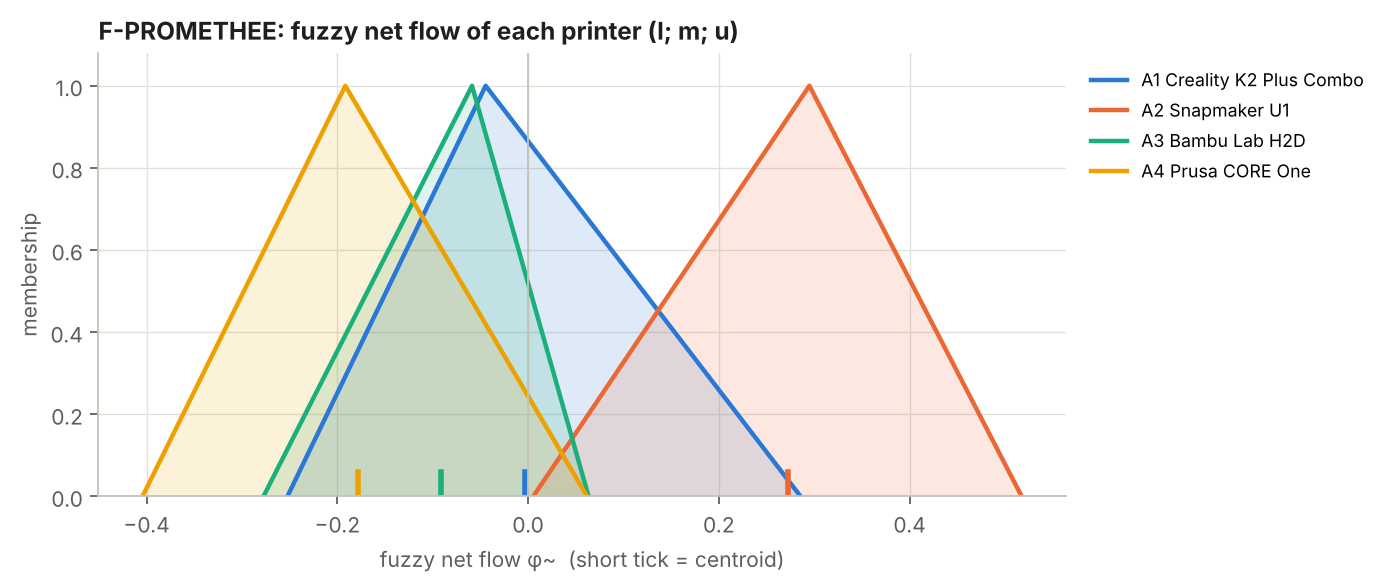

In [22]:
#@title Fuzzy net flows and F-PROMETHEE ranking
display(Markdown("### Fuzzy net flows and F-PROMETHEE ranking"))
table("results/fuzzy_promethee.csv")
display(Image("results/figures/11_f_promethee.png", width=900))

**Interpretation.** Every PROMETHEE step is done on the three numbers (l; m; u), so each printer gets a triangular
net flow; the middle value m is the normal φ. Ranked by the centroid (l + m + u)/3 the order is the
same as before: **U1 > K2 Plus > H2D > Prusa**. U1 is the only printer whose whole triangle is on
the positive side, so even in the worst plausible case it is not worse than average. The K2 Plus
triangle is the widest because its noise value is the most uncertain.

## 8. Conclusion

**I would buy the Snapmaker U1.** It wins in PROMETHEE II and PROMETHEE I, the same as the WSM in
Task 1, it stays first when I change the weights or the thresholds, it is efficient and dominates
the K2 Plus and the Prusa, and it still wins when the uncertain values are fuzzy. The Bambu H2D is
the better machine overall, but for my priorities (price and multi-colour) it is not worth 1226 €
more.